# 09 — Association of recorded crime with urban features

**Question.** Do census tracts with more commercial, education, health and religious addresses, more
residents, higher household-head income or higher literacy also record more bulletins — in place
(Spearman's ρ) and in space (bivariate Moran: does a tract's feature go with its neighbours' crime, and vice
versa)?

**Inputs.** Crime: bulletins per tract 2022–2025 and 2022 alone (the census year), from
`Warehouse.counts`. Features, from `Warehouse.census_tracts()`: CNEFE 2022 address counts by use type
(`n_commercial` = "other purposes", the commerce proxy; `n_education`, `n_health`, `n_religious`), resident
population (IBGE 2022), `income_head_mean` (mean nominal monthly income of household heads, R$) and
`literacy_rate` (share of residents 15+ who can read and write).

**Two scales.** `count` = raw counts per unit; `per_km2` = crime per km² vs feature per km² (address
counts and population; income and literacy are already intensive and appear on the count scale only).
**Raw-count associations partly reflect tract size**: a larger tract has more addresses, more residents and
more bulletins for that reason alone. Densities remove the area component but not the population one;
neither scale is a per-capita risk, and nothing here adjusts for confounding.

**Methods / libraries.**
* Spearman's ρ — `scipy.stats.spearmanr` (Spearman 1904); p-value without spatial adjustment.
* Global bivariate Moran's I — `esda.Moran_BV(x, y, w, permutations=999)`, the correlation of x with the
  spatial lag of y (Wartenberg 1985; Anselin, Syabri & Smirnov 2002), both orders: feature × lag(crime)
  and crime × lag(feature); queen, row-standardised. It mixes the in-place correlation with the
  autocorrelation of the lagged variable, so it is not a test of association beyond the plain correlation.
* Local bivariate Moran — `esda.Moran_Local_BV(crime, commerce, w, permutations=499)` (crime of the tract vs
  the spatial lag of its commerce count), tracts 2022–2025, BH FDR (`statsmodels multipletests`).
  Permutation floor 0.002 → BH needs ≥ n/25 = 104 tracts at the floor.
* No multiple-testing adjustment across the feature × group table.

**Citations.** Spearman, C. (1904). *American Journal of Psychology* 15. Wartenberg, D. (1985). Multivariate
spatial correlation. *Geographical Analysis* 17(4). Anselin, L., Syabri, I. & Smirnov, O. (2002). Visualizing
multivariate spatial correlation with dynamically linked windows. *New Tools for Spatial Data Analysis*,
CSISS.
Benjamini & Hochberg (1995). Esri's bivariate tool (Lee's L) is not used.

In [1]:
import time
import warnings

warnings.filterwarnings("ignore", message=".*island.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
import esda
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from libpysal.weights import Queen, W, w_subset
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import SPATIAL_GROUPS as GROUPS
from crime.data import CrimeQuery, Warehouse

import _mapstyle as ms  # notebooks/_mapstyle.py: basemap, overlay, graticule, scale bar, legends

SEED = 20221
ALPHA = 0.05
BV_PERMUTATIONS = 999
LOCAL_PERMUTATIONS = 499
SUPPORTS = ("tract",)
LAB = {"tract": "census tracts"}
POI = ["n_commercial", "n_education", "n_health", "n_religious"]
EXTENSIVE = POI + ["population"]
INTENSIVE = ["income_head_mean", "literacy_rate"]
OUT = NOTEBOOK_OUTPUTS_DIR / "09_association"
OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time()
ms.setup()

## Feature table per tract

In [2]:
wh = Warehouse()
units = {"tract": wh.census_tracts().rename(columns={"census_tract_id": "unit_id"})}   # unit_id = census tract id

feat = {}
for s in SUPPORTS:
    u = units[s].set_index("unit_id")
    f = u[["n_education", "n_health", "n_commercial", "n_religious"]].copy()
    f["population"] = u["population"]
    for c in INTENSIVE:
        f[c] = u[c]
    f["area_km2"] = u["area_km2"]
    feat[s] = f
    f.to_csv(OUT / f"features_{s}.csv")


def tract_counts(group, **period):
    """Bulletins of one group per tract over the query period, indexed by tract id."""
    c = wh.counts(CrimeQuery(crime_group=group, **period))
    return c.set_index("census_tract_id")["count"].rename_axis("unit_id")


crime = {}
for s in SUPPORTS:
    for g in GROUPS:
        crime[s, g, "2022-2025"] = tract_counts(g).reindex(feat[s].index).astype(float)
        crime[s, g, "2022"] = tract_counts(g, end="2022-12-31").reindex(feat[s].index).astype(float)
feat["tract"].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_education,2592.0,0.42,2.64,0.00,0.00,0.00,0.00,126.00
n_health,2592.0,0.67,3.36,0.00,0.00,0.00,0.00,104.00
n_commercial,2592.0,21.18,30.13,0.00,3.00,11.00,27.00,327.00
n_religious,2592.0,0.72,1.26,0.00,0.00,0.00,1.00,12.00
population,2592.0,439.45,214.52,0.00,304.75,436.00,559.00,1630.00
income_head_mean,2502.0,4686.33,3681.13,1115.33,2283.99,3375.08,5678.72,27295.92
literacy_rate,2502.0,0.98,0.03,0.83,0.97,0.99,1.00,1.00
area_km2,2592.0,0.31,1.69,0.00,0.03,0.06,0.12,32.11


## Spearman's ρ — every group × support × period × feature × scale

In [3]:
def pairs(s):
    for f in EXTENSIVE + (INTENSIVE if s == "tract" else []):
        yield f, "count"
        if f in EXTENSIVE:
            yield f, "per_km2"

def xy(s, g, period, f, scale):
    y = crime[s, g, period]; x = feat[s][f]
    if scale == "per_km2":
        a = feat[s]["area_km2"]; y, x = y / a, x / a
    ok = x.notna() & y.notna()
    return x[ok], y[ok]

rows = []
for s in SUPPORTS:
    for g in GROUPS:
        for period in ("2022-2025", "2022"):
            for f, scale in pairs(s):
                x, y = xy(s, g, period, f, scale)
                r = spearmanr(x, y)
                rows.append(dict(support=s, group=g, period=period, feature=f, scale=scale, n=len(x), rho=r.statistic, p=r.pvalue))
sp = pd.DataFrame(rows)
sp.to_csv(OUT / "spearman.csv", index=False)
sp.query("group == 'all' and period == '2022-2025'").pivot_table(index="feature", columns=["support", "scale"], values="rho").round(3)

support           tract        
scale             count per_km2
feature                        
income_head_mean  0.088     NaN
literacy_rate     0.011     NaN
n_commercial      0.728   0.593
n_education       0.362   0.211
n_health          0.417   0.370
n_religious       0.254   0.113
population        0.159   0.156

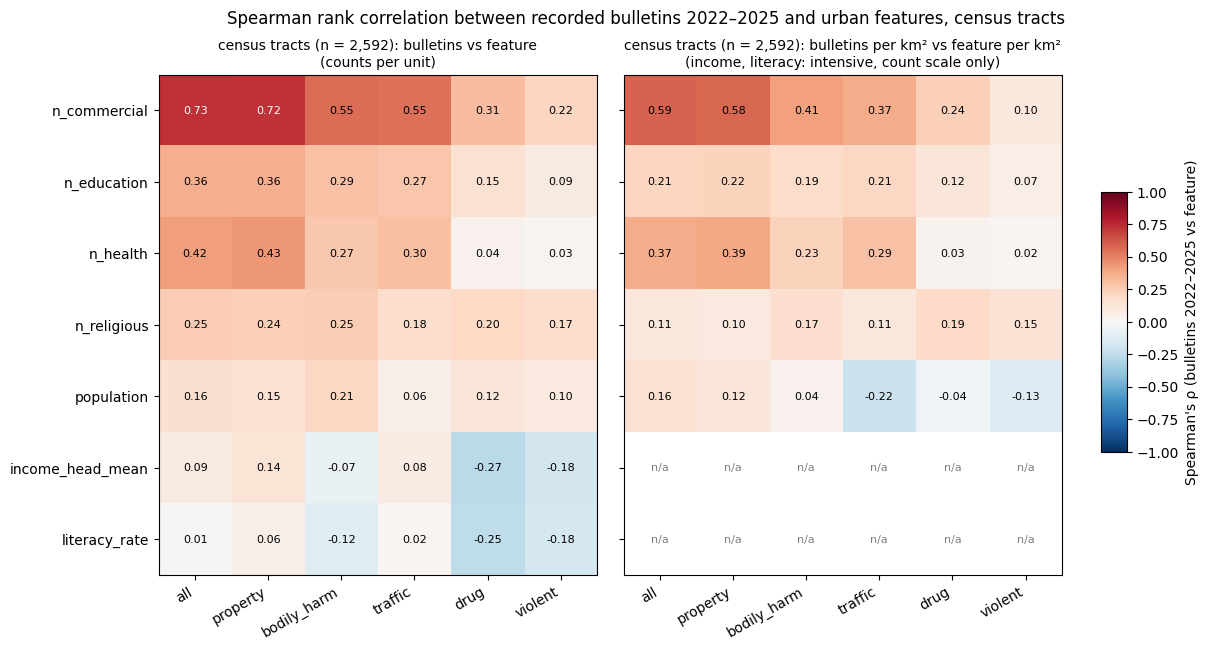

In [4]:
FEATS = EXTENSIVE + INTENSIVE
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
fig.subplots_adjust(wspace=0.06, right=0.82)
panels = [("tract", "count"), ("tract", "per_km2")]
for ax, (s, scale) in zip(axes.ravel(), panels):
    m = (sp.query("support == @s and scale == @scale and period == '2022-2025'")
           .pivot(index="feature", columns="group", values="rho")).reindex(FEATS)[list(GROUPS)]
    im = ax.imshow(np.ma.masked_invalid(m.to_numpy()), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(GROUPS)), GROUPS, rotation=30, ha="right")
    ax.set_yticks(range(len(FEATS)), FEATS if scale == "count" else [])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="0.5" if np.isnan(v) else ("white" if abs(v) > 0.6 else "black"))
    unit = "bulletins vs feature\n(counts per unit)" if scale == "count" else "bulletins per km² vs feature per km²\n(income, literacy: intensive, count scale only)"
    ax.set_title(f"{LAB[s]} (n = {len(units[s]):,}): {unit}", fontsize=10)
cb = fig.colorbar(im, cax=fig.add_axes([0.85, 0.3, 0.02, 0.4])); cb.set_label("Spearman's ρ (bulletins 2022–2025 vs feature)")
fig.suptitle("Spearman rank correlation between recorded bulletins 2022–2025 and urban features, census tracts",
             fontsize=12)
fig.savefig(OUT / "spearman_heatmap.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close(fig)

## Global bivariate Moran's I (queen, 999 permutations, 2022–2025)

Units with a missing feature (income / literacy: 90 tracts) are dropped with `w_subset` for that pair.

In [5]:
wq = {s: Queen.from_dataframe(units[s], ids="unit_id", use_index=False) for s in SUPPORTS}
for s in SUPPORTS:
    assert list(wq[s].id_order) == list(feat[s].index); print(s, "queen islands:", wq[s].islands)

def w_for(s, keep_ids):
    if len(keep_ids) == wq[s].n:
        w = W(wq[s].neighbors, id_order=wq[s].id_order, silence_warnings=True)
    else:
        w = w_subset(wq[s], list(keep_ids), silence_warnings=True)
    w.transform = "r"
    return w

rows = []
for s in SUPPORTS:
    for g in GROUPS:
        for f, scale in pairs(s):
            x, y = xy(s, g, "2022-2025", f, scale)
            w = w_for(s, x.index)
            for order, (a, b) in {"feature x lag(crime)": (x, y), "crime x lag(feature)": (y, x)}.items():
                np.random.seed(SEED)
                bv = esda.Moran_BV(a.to_numpy(), b.to_numpy(), w, permutations=BV_PERMUTATIONS)
                rows.append(dict(support=s, group=g, feature=f, scale=scale, order=order, n=len(x),
                                 I_bv=bv.I, z_sim=bv.z_sim, p_sim=bv.p_sim))
bvt = pd.DataFrame(rows)
bvt.to_csv(OUT / "moran_bv.csv", index=False)
print(f"{len(bvt)} bivariate Moran runs, {time.time() - T0:.0f} s so far")
bvt.query("group == 'all'").pivot_table(index="feature", columns=["support", "scale", "order"], values="I_bv").round(3)

tract queen islands: []


144 bivariate Moran runs, 10 s so far


support                         tract                       \
scale                           count                        
order            crime x lag(feature) feature x lag(crime)   
feature                                                      
income_head_mean                0.051                0.109   
literacy_rate                   0.105                0.153   
n_commercial                    0.300                0.291   
n_education                     0.044                0.033   
n_health                        0.177                0.176   
n_religious                     0.022               -0.003   
population                     -0.053               -0.097   

support                                                     
scale                         per_km2                       
order            crime x lag(feature) feature x lag(crime)  
feature                                                     
income_head_mean                  NaN                  NaN  
literacy_rate                     NaN                  NaN  
n_commercial                    0.539                0.557  
n_education                     0.135                0.154  
n_health                        0.308                0.303  
n_religious                     0.044                0.045  
population                      0.096                0.128

## Local bivariate Moran: tract crime vs the spatial lag of commerce

`esda.Moran_Local_BV(x = bulletins 2022–2025, y = n_commercial, w = queen row-standardised,
permutations = 499)`; quadrants: HH = many bulletins in a tract surrounded by many commercial addresses,
LL = few / few, HL = many bulletins among few commercial addresses, LH = few among many. unadjusted p < 0.05 (left) and BH-FDR q < 0.05 (right).

In [6]:
QUAD = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
# colour + hatch: clusters solid, outliers hatched (as in 05)
STYLE = {"HH": ("#d7191c", ""), "LL": ("#2c7bb6", ""), "HL": ("#fdae61", "//"), "LH": ("#abd9e9", "\\\\"),
         "ns": ("#d9d9d9", "")}
NAME = {"HH": "HH: many bulletins, many commercial addresses around", "LL": "LL: few / few",
        "HL": "HL: many bulletins, few commercial around", "LH": "LH: few bulletins, many commercial around",
        "ns": "not significant"}
w = w_for("tract", feat["tract"].index)
local_rows, local_lab = [], {}
for scale in ("count", "per_km2"):
    x, y = xy("tract", "all", "2022-2025", "n_commercial", scale)
    lbv = esda.Moran_Local_BV(y.to_numpy(), x.to_numpy(), w, permutations=LOCAL_PERMUTATIONS, seed=SEED, keep_simulations=False)
    q = multipletests(lbv.p_sim, alpha=ALPHA, method="fdr_bh")[1]
    quad = np.vectorize(QUAD.get)(lbv.q)
    raw = np.where(lbv.p_sim <= ALPHA, quad, "ns"); fdr = np.where(q <= ALPHA, quad, "ns")
    local_lab[scale] = pd.DataFrame({"unit_id": y.index, "Ii": lbv.Is, "p_sim": lbv.p_sim, "q_bh": q, "raw": raw, "fdr": fdr})
    r = dict(scale=scale, n=len(y), min_p=lbv.p_sim.min(), n_at_floor=int(np.isclose(lbv.p_sim, 1 / (LOCAL_PERMUTATIONS + 1)).sum()),
             floor_units_needed_for_bh=int(np.ceil(len(y) / 25)))
    for c in ("HH", "LL", "HL", "LH"):
        r[f"{c}_raw"] = int((raw == c).sum()); r[f"{c}_fdr"] = int((fdr == c).sum())
    # esda zero ties: own crime 0 and every neighbour's commerce 0
    nb0 = np.array([x.loc[w.neighbors[i]].sum() == 0 for i in w.id_order])
    allzero = (y.to_numpy() == 0) & nb0
    r["LL_raw_allzero"] = int(((raw == "LL") & allzero).sum()); r["LL_fdr_allzero"] = int(((fdr == "LL") & allzero).sum())
    local_rows.append(r)
    local_lab[scale].to_csv(OUT / f"local_bv_crime_commerce_tract_{scale}.csv", index=False)
loc = pd.DataFrame(local_rows)
loc.to_csv(OUT / "local_bv_counts.csv", index=False)
loc

,scale,n,min_p,n_at_floor,floor_units_needed_for_bh,HH_raw,HH_fdr,LL_raw,LL_fdr,HL_raw,HL_fdr,LH_raw,LH_fdr,LL_raw_allzero,LL_fdr_allzero
0,count,2592,0.002,64,104,223,0,187,0,16,0,106,0,2,0
1,per_km2,2592,0.002,150,104,155,33,441,169,32,7,32,2,3,3


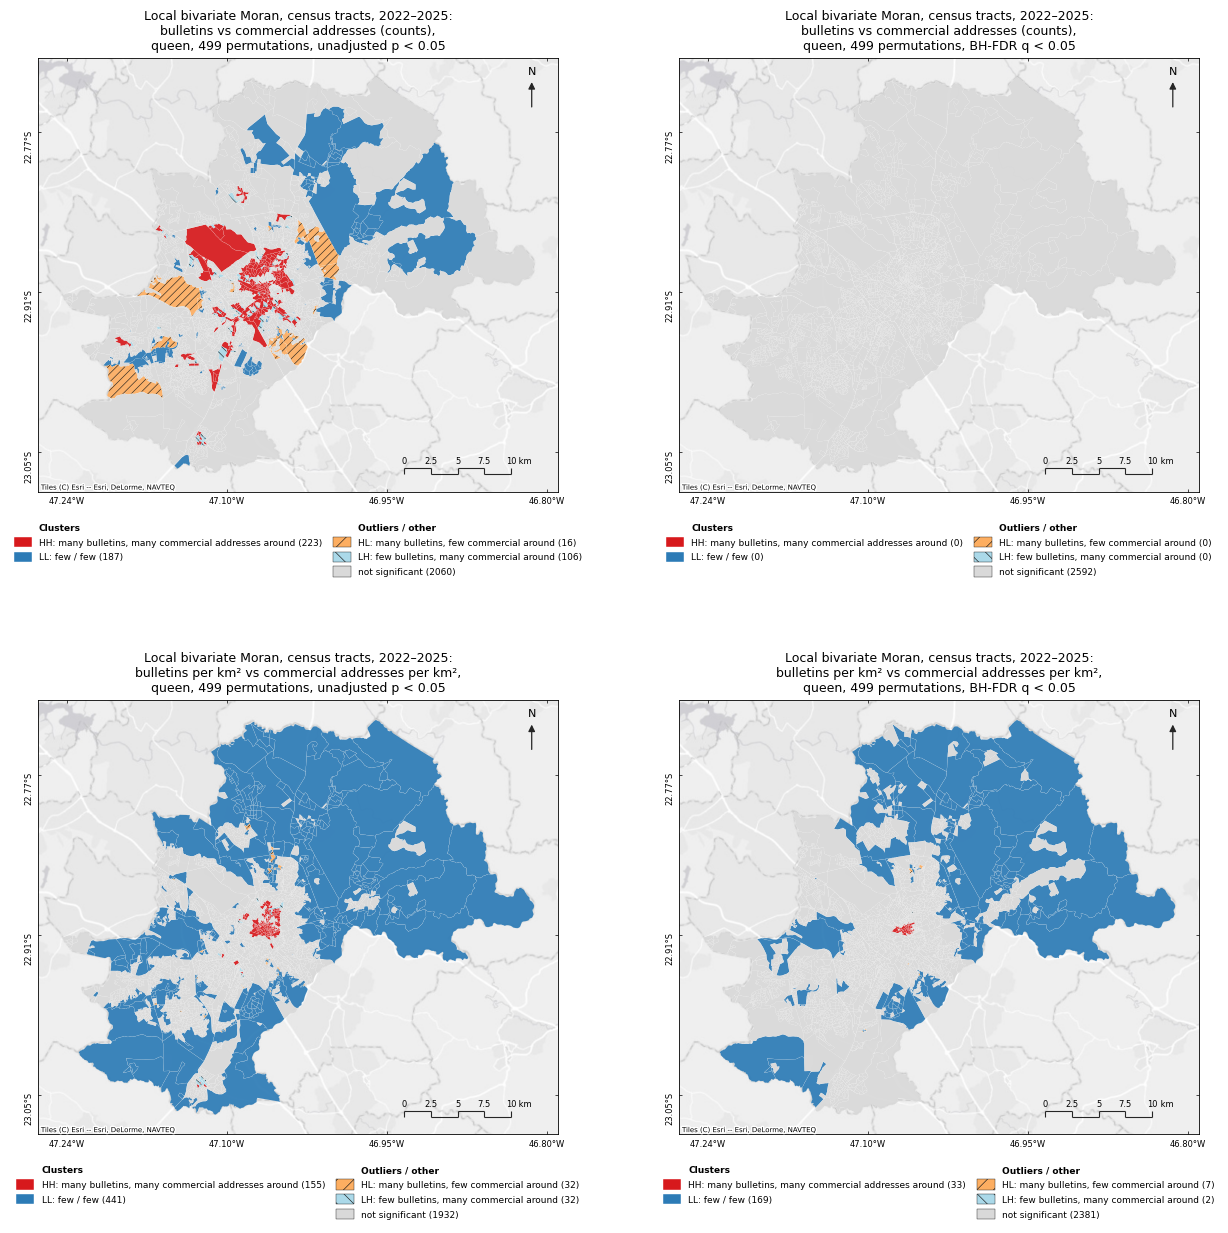

runtime 20 s


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for i, scale in enumerate(("count", "per_km2")):
    for j, which in enumerate(("raw", "fdr")):
        ax = axes[i, j]
        lab = units["tract"]["unit_id"].map(local_lab[scale].set_index("unit_id")[which])
        ms.plot_categories(ax, units["tract"], lab.to_numpy(), STYLE, hatch_repeat=2, linewidth=0.05)
        ms.decorate(ax, units["tract"].crs)
        vc = lab.value_counts()
        ms.category_legend(ax, {"Clusters": [(NAME[c], *STYLE[c]) for c in ("HH", "LL")],
                                "Outliers / other": [(NAME[c], *STYLE[c]) for c in ("HL", "LH", "ns")]},
                           counts={NAME[c]: vc.get(c, 0) for c in NAME}, bbox=(0.5, -0.05), fontsize=6.5)
        sc = "bulletins vs commercial addresses (counts)" if scale == "count" else "bulletins per km² vs commercial addresses per km²"
        thr = "BH-FDR q < 0.05" if which == "fdr" else "unadjusted p < 0.05"
        ax.set_title(f"Local bivariate Moran, census tracts, 2022–2025:\n{sc},\nqueen, 499 permutations, {thr}", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "local_bv_crime_commerce_tract.png", dpi=300)
plt.show(); plt.close(fig)
print(f"runtime {time.time() - T0:.0f} s")

In [8]:
# numbers quoted in the Findings cell
pd.set_option("display.width", 200)
print(sp.query("period == '2022-2025'").pivot_table(index=["support", "feature"], columns=["scale", "group"], values="rho").round(2).to_string())
print(sp.query("group == 'all'").pivot_table(index=["support", "feature", "scale"], columns="period", values="rho").round(3).to_string())
print(bvt.query("group == 'all'").pivot_table(index=["support", "feature", "scale"], columns="order", values=["I_bv", "p_sim"]).round(3).to_string())
print("Spearman p > 0.05:", sp.query("p > 0.05")[["support", "group", "period", "feature", "scale", "rho", "p"]].to_string(index=False))

scale                    count                                            per_km2                                           
group                      all bodily_harm  drug property traffic violent     all bodily_harm  drug property traffic violent
support feature                                                                                                             
tract   income_head_mean  0.09       -0.07 -0.27     0.14    0.08   -0.18     NaN         NaN   NaN      NaN     NaN     NaN
        literacy_rate     0.01       -0.12 -0.25     0.06    0.02   -0.18     NaN         NaN   NaN      NaN     NaN     NaN
        n_commercial      0.73        0.55  0.31     0.72    0.55    0.22    0.59        0.41  0.24     0.58    0.37    0.10
        n_education       0.36        0.29  0.15     0.36    0.27    0.09    0.21        0.19  0.12     0.22    0.21    0.07
        n_health          0.42        0.27  0.04     0.43    0.30    0.03    0.37        0.23  0.03     0.39    0.29    0.02


## Findings

*Numbers from the cells above (seed 20221); CSVs in `outputs/nb/09_association/`. No adjustment for
multiple testing across this table, and none for confounding.*

- **Commerce is the strongest tract-level correlate.** All groups, 2022–2025, tracts: Spearman ρ with
  commercial addresses = **0.728** on counts and **0.593** per km²; with health addresses 0.417 / 0.370,
  education 0.362 / 0.211, religious 0.254 / 0.113, population 0.159 / 0.156. The drop from counts to
  densities is the part of the association due to tract size.
- **Income and literacy (tracts, count scale)** are weakly related to the total (ρ = 0.088 and 0.011, the
  latter not significant, p = 0.57), but **drug** (ρ = −0.269 / −0.254) and **violent** (−0.184 / −0.179)
  bulletins are more frequent in poorer, less literate tracts, and property slightly more frequent in richer ones
  (0.140 / 0.059).
- **Population per km² vs bulletins per km²** is negative for traffic (−0.218), violent (−0.129) and drug
  (−0.042): those bulletins concentrate in commercial / transit areas rather than residential density.
- **2022 vs 2022–2025** gives nearly the same ρ (all groups, commerce on tracts: 0.694 vs 0.728).
- **Global bivariate Moran (queen).** Commerce: I_BV = 0.300 (crime × lag commerce) and 0.291 (commerce ×
  lag crime) on tract counts and 0.539 / 0.557 per km² (all p_sim = 0.001).
  Population on tract counts is slightly **negative** (−0.053 / −0.097): tracts with many residents sit
  next to tracts with fewer bulletins. Religious addresses on tract counts are not significant
  (p_sim = 0.051 / 0.379). These values mix the in-place correlation with the spatial autocorrelation of
  the lagged variable; they do not show an association beyond the plain correlation.
- **Local bivariate Moran, tract crime vs lag of commerce.** On **counts BH rejects nothing**: only 63 tracts
  reach the 0.002 permutation floor and BH needs 104, although 223 HH, 188 LL, 16 HL and 106 LH tracts have
  unadjusted p < 0.05. **Per km²** 149 tracts reach the floor, and BH keeps **33 HH** (a compact central
  cluster), **168 LL** (mostly large, sparsely built peripheral tracts), 7 HL and 2 LH (raw: 155 / 440 / 32 / 32).
  Only 2 raw LL tracts (0 after BH) have zero bulletins and zero commercial addresses around them
  (the esda zero-tie case).